# 4 个模型 × 前 10 个主成分的 Shapley 寄与图

同样的 5 张眼底图（每个 DR 等级画质最好的 1 张），分别输入 SigLIP、MedSigLIP、ConceptCLIP、FLAIR，求前 10 个主成分得分的寄与图，按图像把 4 个模型并排比较。算法和设定与 `rise_shapley.ipynb` 相同：参照为视野内的高斯模糊，grid 14、16,000 张遮罩，保留概率 q 取自 U(0, 1)。

- **主成分的正方向**：每个主成分取与它相关最强的标签（重症度、左右眼、清晰度、伪影），正方向与该标签一致。图上每格左上角的小字即为该标签和 |ρ|，例如 `DR+ .79` 表示正方向 = 重症一侧。
- **视野**：由各模型自己的输入求出（`model_view`），与模型如何缩放、裁剪、补边无关。
- **模糊强度**：σ = 16 px 按 448 px 的输入换算，输入为 384 或 512 px 的模型按比例调整。
- **色标**：每格各自计算（视野内 |值| 的 99% 分位），左上角 ± 后为该格的上限，底部色条为相对刻度。不同模型、不同主成分的寄与大小不同，统一色标时弱的格子会看不见。

先运行初始化格；其余各格只依赖它。结果存在 `results/rise/<model>/shapley_pc10_…/<image_id>.npz`：`sal` [10, H, W]、`s0`、`s_ref`、`view`（模型看到的图像）。

In [1]:
import gc

import numpy as np
import pandas as pd
import torch
from PIL import Image

from fmspace.analysis import l2, pc_scorer, pca, rho
from fmspace.data import load_metadata
from fmspace.extract import load_features
from fmspace.models import MODELS, load_model
from fmspace.paths import DATA_DIR, FEATURE_DIR, FIGURE_DIR, RISE_DIR
from fmspace.plots import MODEL_NAMES, saliency_figure
from fmspace.rise import fov_blur, model_view, rise_shapley

N_PCS = 10
LABELS = {"eye_dr_level": "DR", "eye": "R", "clarity": "Clarity", "artifact": "Artifact"}  # 定正方向的候选标签 → 图上的简称
# N_MASKS, GRID, SEED, SIGMA = 16000, 14, 0, 16  # SIGMA：448 px 输入时的模糊强度
N_MASKS, GRID, SEED, SIGMA = 8000, 8, 0, 16  # SIGMA：448 px 输入时的模糊强度
QUALITY = {"overall_quality": False, "artifact": True, "clarity": False, "field_definition": False}  # 排序列 → 是否升序

metadata = load_metadata(DATA_DIR).set_index("image_id", drop=False)
selected = (metadata.sort_values(list(QUALITY), ascending=list(QUALITY.values()))
                    .groupby("eye_dr_level").head(1).sort_values("eye_dr_level"))

fitted, signs, aligned = {}, {}, {}
for name in MODELS:
    X = l2(load_features(FEATURE_DIR / f"{name}.npz", metadata["image_id"]))
    fitted[name] = pca(X)
    pcs = fitted[name].transform(X)[:, :N_PCS]
    r = pd.DataFrame({l: [rho(pcs[:, k], metadata[l].rank()) for k in range(N_PCS)] for l in LABELS})
    best = r.abs().idxmax(axis=1)
    aligned[name] = [(l, abs(r.at[k, l])) for k, l in enumerate(best)]
    signs[name] = np.sign([r.at[k, l] for k, l in enumerate(best)])

OUT = {name: RISE_DIR / name / f"shapley_pc{N_PCS}_grid{GRID}_n{N_MASKS}_blur{SIGMA}" for name in MODELS}
pd.DataFrame({MODEL_NAMES[n]: [f"{LABELS[l]}+ {v:.2f}" for l, v in aligned[n]] for n in MODELS}, index=[f"PC{k + 1}" for k in range(N_PCS)])

/home/tsakailab/workspace/WZX/fm_space/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,SigLIP,MedSigLIP,ConceptCLIP,FLAIR
PC1,DR+ 0.65,DR+ 0.79,DR+ 0.61,DR+ 0.78
PC2,Clarity+ 0.53,R+ 0.80,R+ 0.84,DR+ 0.30
PC3,DR+ 0.33,Clarity+ 0.47,Clarity+ 0.57,Artifact+ 0.24
PC4,Artifact+ 0.47,Artifact+ 0.22,DR+ 0.28,DR+ 0.11
PC5,DR+ 0.13,Artifact+ 0.35,Artifact+ 0.05,DR+ 0.14
PC6,DR+ 0.21,Clarity+ 0.27,DR+ 0.25,Artifact+ 0.12
PC7,Artifact+ 0.24,Clarity+ 0.36,Artifact+ 0.17,Clarity+ 0.22
PC8,Artifact+ 0.18,Clarity+ 0.17,Clarity+ 0.05,Artifact+ 0.13
PC9,Clarity+ 0.27,DR+ 0.13,Artifact+ 0.14,Artifact+ 0.25
PC10,DR+ 0.14,Artifact+ 0.16,Clarity+ 0.08,Clarity+ 0.13


## 跑 Shapley 寄与图

模型逐个加载，用完释放显存。已有结果的图跳过。

In [2]:
for name in MODELS:
    todo = [i for i in selected.index if not (OUT[name] / f"{i}.npz").exists()]
    if not todo:
        continue
    OUT[name].mkdir(parents=True, exist_ok=True)
    preprocess, forward = load_model(name, "cuda")
    model = pc_scorer(torch.autocast("cuda", dtype=torch.float16)(forward), fitted[name], range(1, N_PCS + 1), signs[name])
    for image_id in todo:
        x, fov, view = model_view(preprocess, Image.open(metadata["path"][image_id]).convert("RGB"))
        baseline = fov_blur(x, fov.to(x), SIGMA * x.shape[-1] / 448)
        sal = rise_shapley(model, x, baseline, N=N_MASKS, s=GRID, seed=SEED)
        with torch.inference_mode():
            s0, s_ref = model(x)[0], model(baseline)[0]
        np.savez(OUT[name] / f"{image_id}.npz", sal=sal.numpy(), s0=s0.numpy(), s_ref=s_ref.numpy(), view=np.asarray(view))
    del preprocess, forward, model
    gc.collect()
    torch.cuda.empty_cache()

Loading weights: 100%|██████████| 448/448 [00:00<00:00, 8482.90it/s]
[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-so400m-patch14-384
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...26}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.v_

## 汇总

`total` 是寄与图总和（按格子面积换算），应等于 `s0 − s_ref`。下表是各模型、各主成分的 `ratio = total / (s0 − s_ref)` 在 5 张图上的中位数，≈ 1 即守恒成立。`s0 − s_ref` 很小的主成分（参照与原图得分几乎相同）ratio 会不稳定。

In [3]:
rows = []
for name in MODELS:
    for image_id in selected.index:
        d = np.load(OUT[name] / f"{image_id}.npz")
        h, w = d["sal"].shape[1:]
        cell = ((GRID + 1) * np.ceil(h / GRID) / GRID) * ((GRID + 1) * np.ceil(w / GRID) / GRID)
        for k in range(N_PCS):
            s0, s_ref, total = d["s0"][k], d["s_ref"][k], d["sal"][k].sum() / cell
            rows.append({"model": name, "image_id": image_id, "dr": metadata["eye_dr_level"][image_id], "pc": k + 1,
                         "label": aligned[name][k][0], "s0": s0, "s_ref": s_ref, "total": total, "ratio": total / (s0 - s_ref)})
summary = pd.DataFrame(rows)
summary.to_csv(RISE_DIR / f"shapley_pc{N_PCS}_summary.csv", index=False)
summary.pivot_table(index="model", columns="pc", values="ratio", aggfunc="median").round(2)

pc,1,2,3,4,5,6,7,8,9,10
model,,,,,,,,,,
conceptclip,1.03,1.07,0.99,1.04,1.05,1.05,0.73,1.04,1.01,0.92
flair,1.02,1.02,0.92,1.09,1.03,1.11,0.95,1.29,0.98,1.25
medsiglip,1.03,0.91,0.96,0.89,1.00,0.96,1.06,0.99,1.06,0.93
siglip,0.98,0.96,0.95,1.01,0.76,1.05,1.00,0.95,0.73,0.98


## 画图

每张图一幅：每行一个模型，左为模型看到的图像，右为 PC1–PC10 的寄与图。

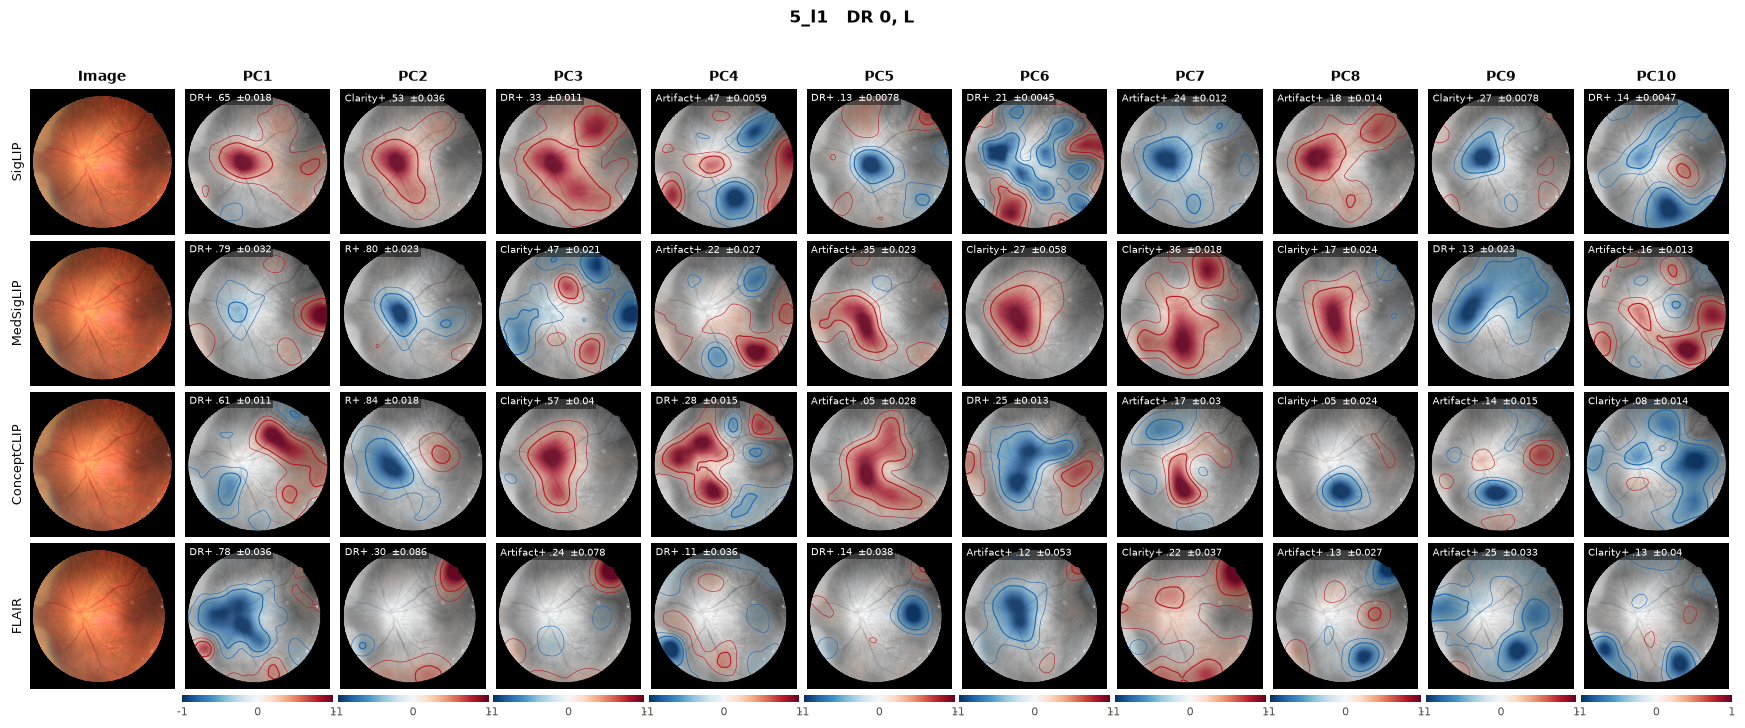

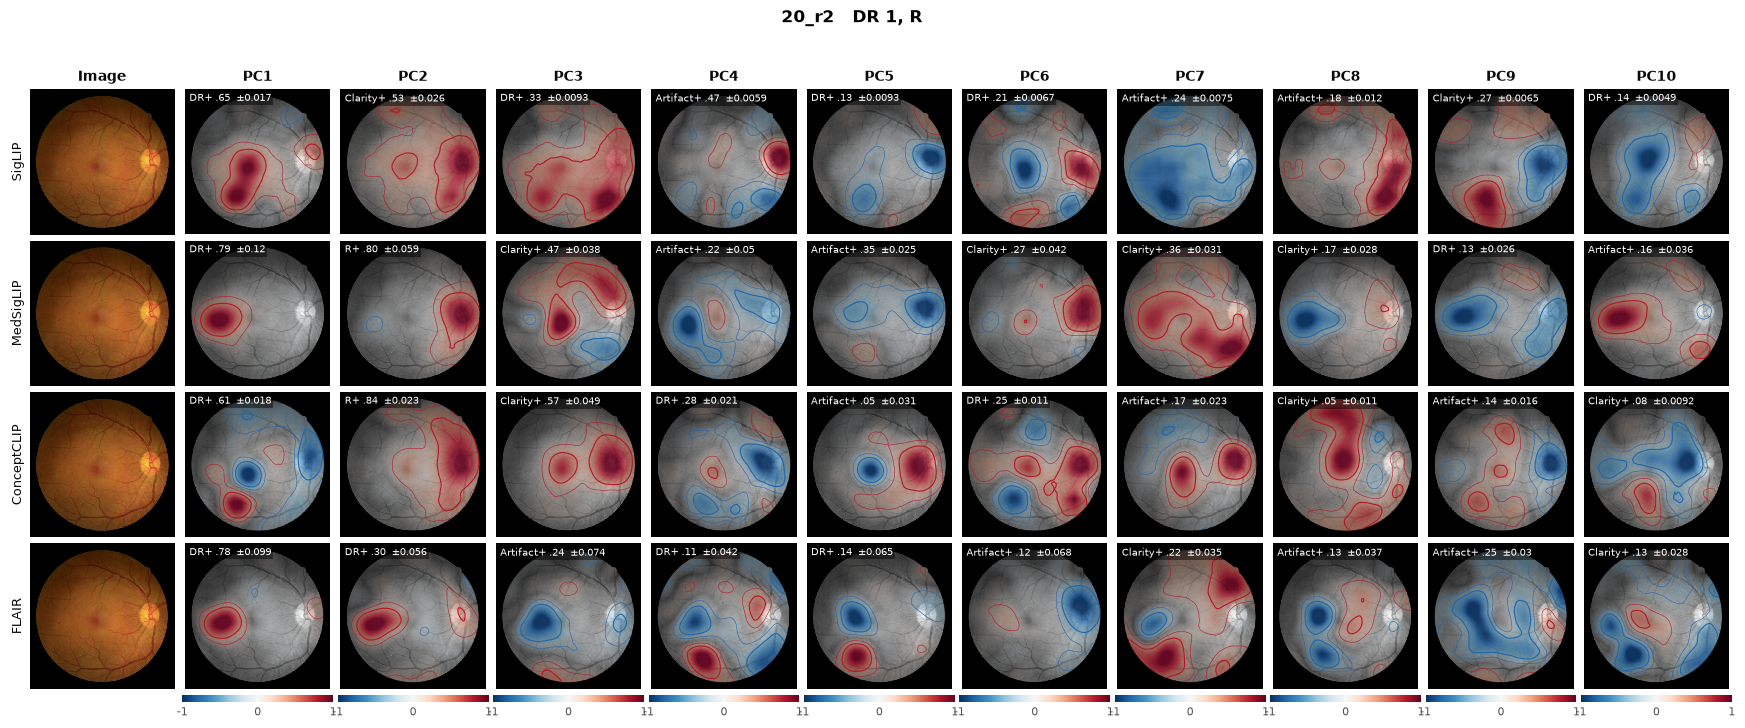

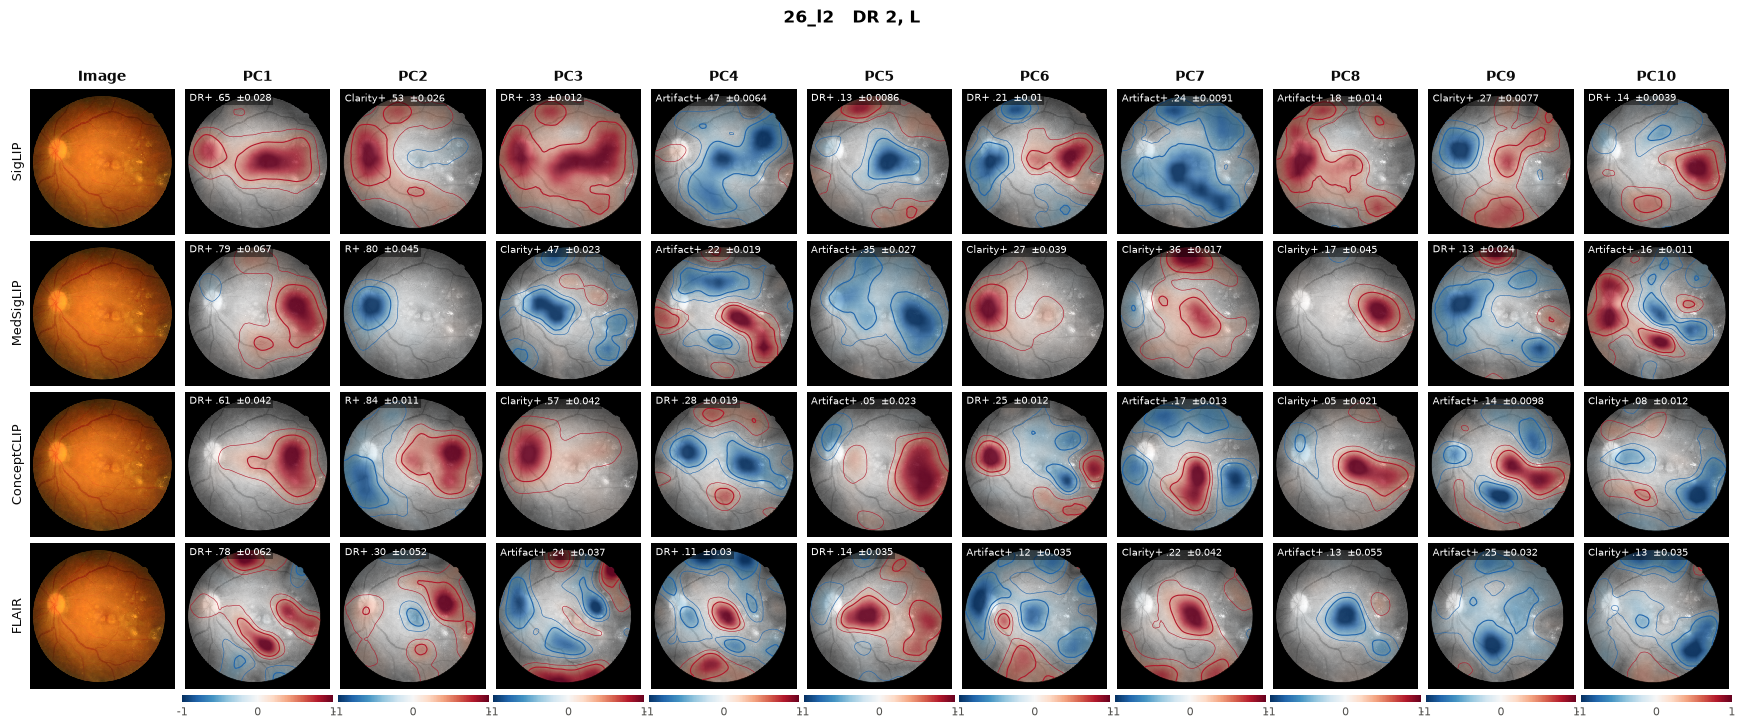

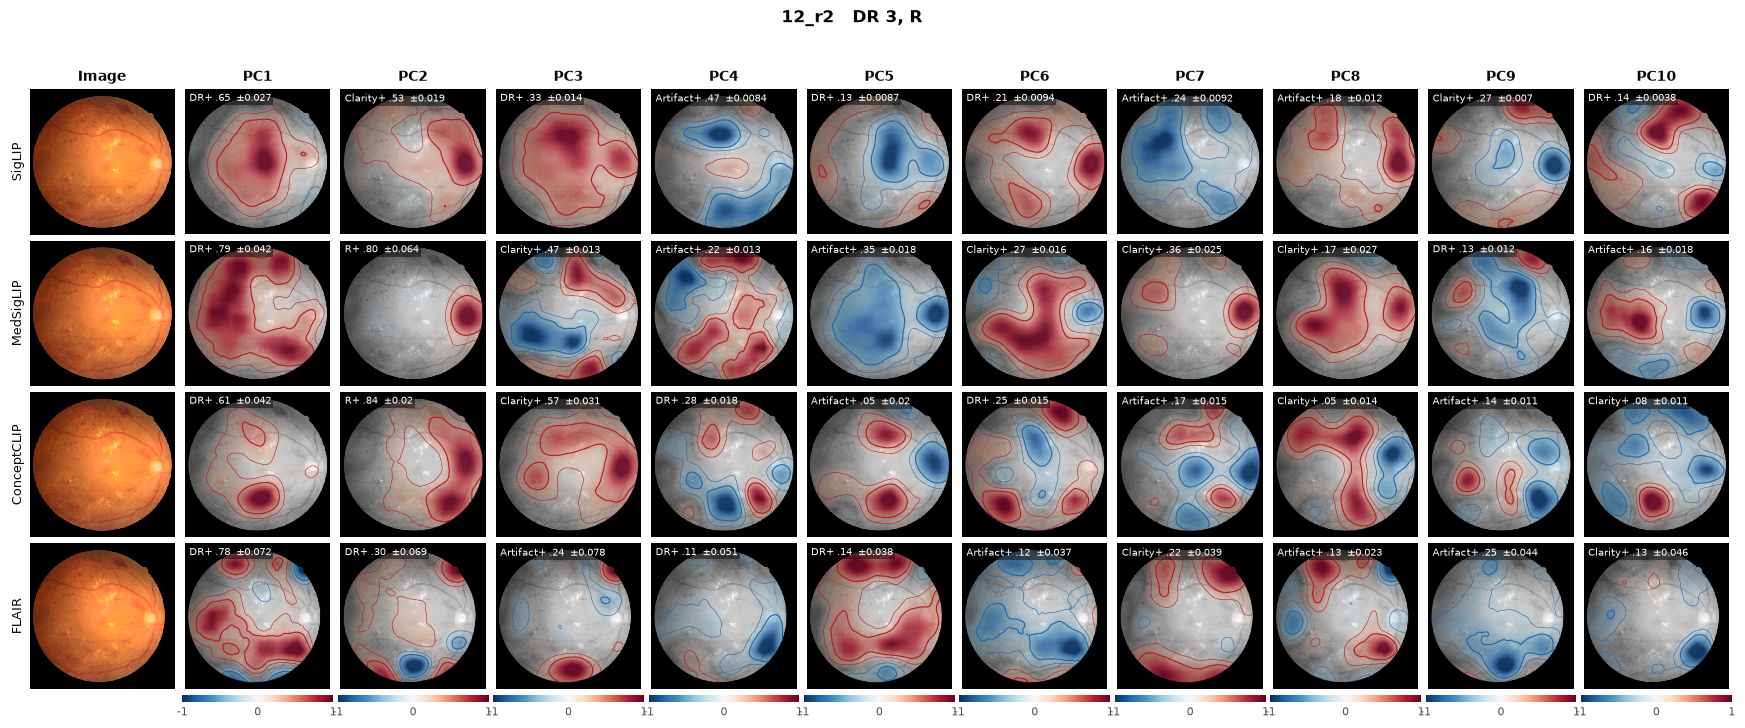

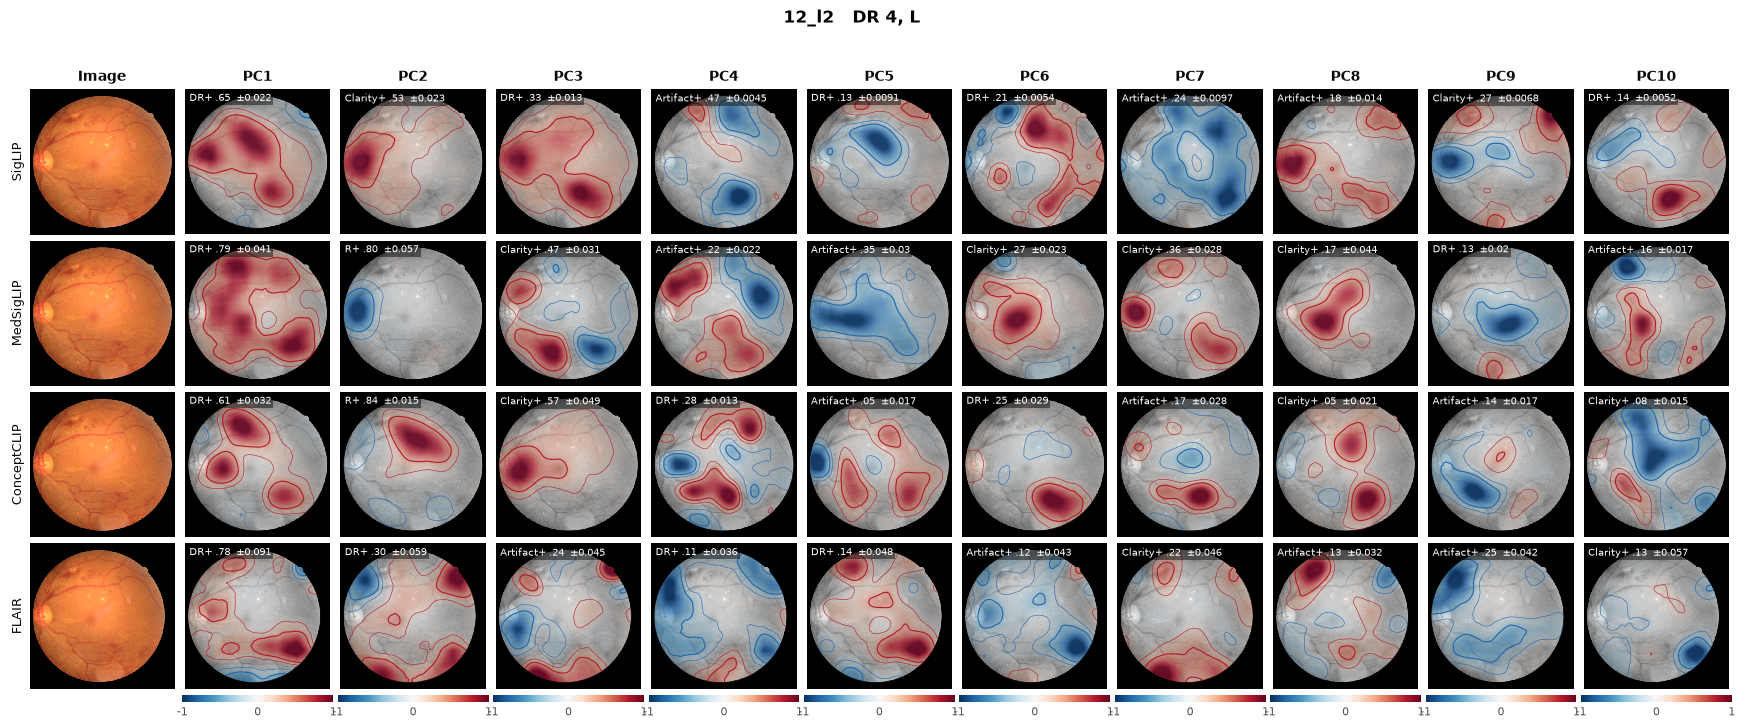

In [6]:
for image_id in selected.index:
    maps = [np.load(OUT[name] / f"{image_id}.npz") for name in MODELS]
    tags = [[f"{LABELS[l]}+ {v:.2f}".replace("0.", ".") for l, v in aligned[name]] for name in MODELS]
    fig = saliency_figure([Image.fromarray(m["view"]) for m in maps], [m["sal"] for m in maps], [MODEL_NAMES[n] for n in MODELS],
                          [f"PC{k + 1}" for k in range(N_PCS)], panel=2.0, panel_labels=tags, scale="panel")
    fig.suptitle(f"{image_id}   DR {metadata['eye_dr_level'][image_id]}, {metadata['eye'][image_id]}", fontweight="bold")
    out = FIGURE_DIR / f"n={N_MASKS}_g={GRID}"
    out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out/ f"shapley_pc{N_PCS}_{image_id}.png", dpi=300, bbox_inches="tight")